Imports

In [7]:
import sys
sys.path.append('..')

from data_prep import load_raw_data, rescale_features, get_X_y, FEATURE_COLS, LABEL_COL
from pqc import build_full_pqc
from training import qnn_output, cost_function, train, evaluate

Load and Inspect

In [8]:
df = load_raw_data()
print(df.shape)
print(df[LABEL_COL].value_counts(normalize=True))
df.head()

(3415, 11)
Hematologist Remarks
0    0.826354
1    0.173646
Name: proportion, dtype: float64


,GENDER,RBC Count (mil/cmm),Hemoglobin Level (g/dL),Hematocrit (%),MCV (fL),MCH (pg),MCHC (g/dL),RDW-CV (%),Hemoglobin A (%),Hemoglobin A2 (%),Hematologist Remarks
0,0,3.87,10.4,32.0,83,27,32,14,97.6,2.4,0
1,0,4.53,6.3,23.0,51,14,27,23,98.3,1.7,0
2,0,4.14,9.1,29.0,71,22,31,19,97.8,2.2,0
3,0,4.01,11.0,34.0,84,28,33,17,97.7,2.3,0
4,0,3.42,7.4,24.0,69,22,31,17,95.1,4.9,1


Distribution by Class

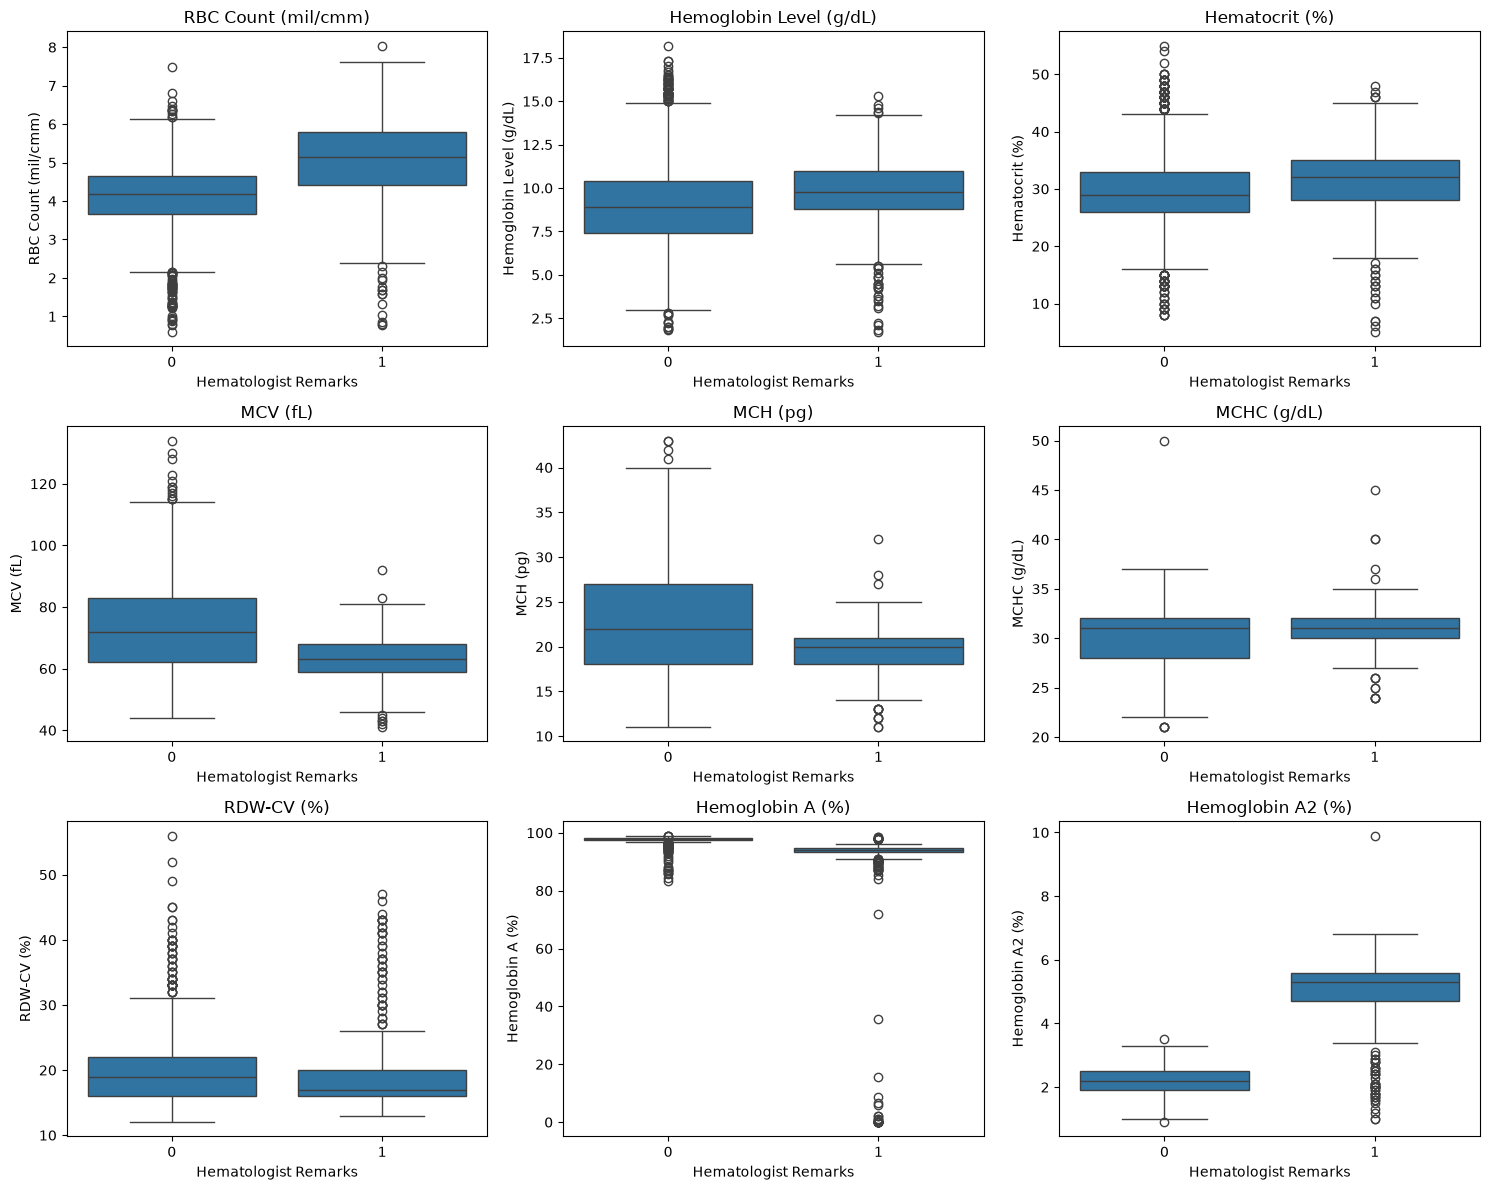

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = [c for c in FEATURE_COLS if c != 'GENDER']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(data=df, x=LABEL_COL, y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Correlation Matrix

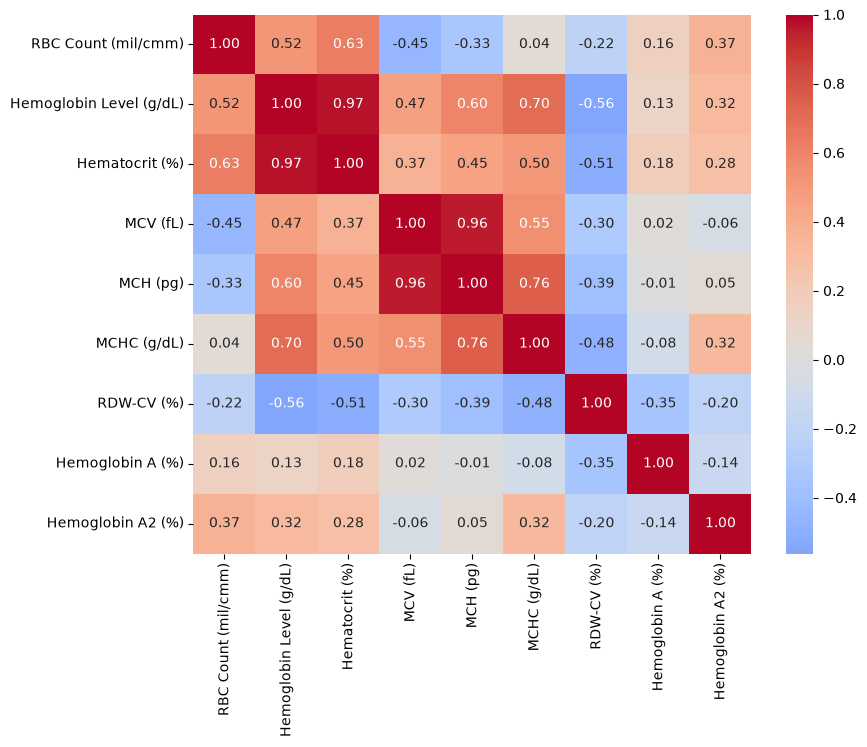

In [10]:
corr = df[numeric_cols].corr()
plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt=".2f")
plt.show()

Classical Baseline

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

X, y = get_X_y(df, FEATURE_COLS)

for name, model in [('Logistic Regression', LogisticRegression(max_iter=1000)),
                     ('Linear SVM', SVC(kernel='linear')),
                     ('RBF SVM', SVC(kernel='rbf'))]:
    scores = cross_val_score(model, X, y, cv=5)
    print(f"{name}: {scores.mean():.3f} ± {scores.std():.3f}")

Logistic Regression: 0.995 ± 0.002
Linear SVM: 0.995 ± 0.002
RBF SVM: 0.979 ± 0.004


Feature Importance

Hemoglobin A2 (%)          0.517943
Hemoglobin A (%)           0.320402
RBC Count (mil/cmm)        0.051880
MCV (fL)                   0.032718
MCH (pg)                   0.023644
MCHC (g/dL)                0.015854
RDW-CV (%)                 0.014627
Hemoglobin Level (g/dL)    0.014377
Hematocrit (%)             0.006787
GENDER                     0.001768
dtype: float64


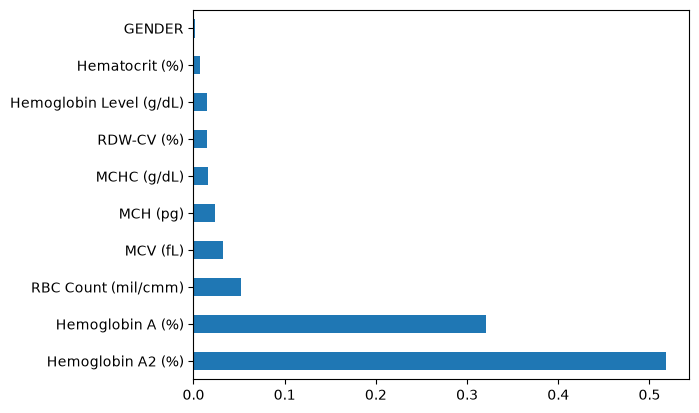

In [12]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

rf = RandomForestClassifier(random_state=42).fit(X, y)
importances = pd.Series(rf.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
print(importances)
importances.plot(kind='barh')
plt.show()